# 01 — UNSW-NB15 Dataset Inspection (AI-01)

Inspect the dataset before building any model:
1. Size, schema, and column types
2. Missing values, duplicates, and train/test leakage
3. Class balance and feature skew
4. Single-feature signal and dataset artefacts (`sttl`)

## 1. Setup & load data

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import balanced_accuracy_score
from sklearn.tree import DecisionTreeClassifier

DATA_DIR = Path("../datasets/unsw_nb15")
COLORS = {0: "#2a78d6", 1: "#eb6834"}  # normal = blue, attack = orange
NAMES = {0: "normal", 1: "attack"}

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

train = pd.read_csv(DATA_DIR / "UNSW_NB15_training-set.csv")
test = pd.read_csv(DATA_DIR / "UNSW_NB15_testing-set.csv")

print(f"Train: {train.shape[0]:,} rows x {train.shape[1]} columns")
print(f"Test:  {test.shape[0]:,} rows x {test.shape[1]} columns")

Train: 175,341 rows x 45 columns
Test:  82,332 rows x 45 columns


Each row is one network flow: `id`, 42 measured features, and two targets (`attack_cat`, `label`). Row counts match the spec (175,341 train / 82,332 test).

## 2. Sample rows

In [2]:
train.head()

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,...,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.121478,tcp,-,FIN,6,4,258,172,74.087490,...,1,1,0,0,0,1,1,0,Normal,0
1,2,0.649902,tcp,-,FIN,14,38,734,42014,78.473372,...,1,2,0,0,0,1,6,0,Normal,0
2,3,1.623129,tcp,-,FIN,8,16,364,13186,14.170161,...,1,3,0,0,0,2,6,0,Normal,0
3,4,1.681642,tcp,ftp,FIN,12,12,628,770,13.677108,...,1,3,1,1,0,2,1,0,Normal,0
4,5,0.449454,tcp,-,FIN,10,6,534,268,33.373826,...,1,40,0,0,0,2,39,0,Normal,0


## 3. Column types
Numeric columns (`int64`, `float64`) go directly into models. Text columns (`str`) are categories and need encoding first.

In [3]:
print("Column counts by dtype:")
print(train.dtypes.value_counts().to_string())
print("\nUnique values in text columns:")
print(train.select_dtypes("str").nunique().to_string())

Column counts by dtype:
int64      30
float64    11
str         4

Unique values in text columns:
proto         133
service        13
state           9
attack_cat     10


## 4. Missing values
Check both empty cells (`NaN`) and placeholder values — `service` uses `"-"` to mean *unknown*.

In [4]:
print(f"Empty cells — train: {train.isna().sum().sum()}, test: {test.isna().sum().sum()}")
print(f"service == '-' — train: {(train['service'] == '-').mean():.1%}, test: {(test['service'] == '-').mean():.1%}")

Empty cells — train: 0, test: 0
service == '-' — train: 53.7%, test: 57.3%


## 5. Duplicates & train/test overlap
Ignoring `id`, exact duplicate rows let a model memorize repeated examples. Rows appearing in **both** train and test cause **leakage** and inflate test scores.

In [5]:
feature_cols = train.columns.drop("id")
train_dups = train.duplicated(subset=feature_cols).sum()
test_dups = test.duplicated(subset=feature_cols).sum()
overlap = len(test[feature_cols].merge(train[feature_cols].drop_duplicates(), how="inner"))

print(f"Duplicate rows in train: {train_dups:,} ({train_dups / len(train):.1%})")
print(f"Duplicate rows in test:  {test_dups:,} ({test_dups / len(test):.1%})")
print(f"Test rows also in train: {overlap:,} ({overlap / len(test):.1%} of test)")

Duplicate rows in train: 67,601 (38.6%)
Duplicate rows in test:  26,387 (32.0%)
Test rows also in train: 4,247 (5.2% of test)


## 6. Class balance & attack categories
`label` is `0` (normal) or `1` (attack). Because attacks make up 68% of train, accuracy alone is misleading — evaluate with **precision, recall, F1, and false-positive rate (FPR)**.

In [6]:
balance = pd.DataFrame({
    "train": train["label"].value_counts(normalize=True),
    "test": test["label"].value_counts(normalize=True),
}).rename(index=NAMES)

balance.style.format("{:.1%}")

,train,test
label,,
attack,68.1%,55.1%
normal,31.9%,44.9%


`attack_cat` breaks attacks into families. It is **excluded** from binary model inputs (it leaks the answer), but shows which attack types have plenty vs. few examples.

In [7]:
cats = pd.DataFrame({
    "train": train["attack_cat"].value_counts(),
    "test": test["attack_cat"].value_counts(),
})
cats.style.format("{:,}")

,train,test
attack_cat,,
Normal,"56,000","37,000"
Generic,"40,000","18,871"
Exploits,"33,393","11,132"
Fuzzers,"18,184","6,062"
DoS,"12,264","4,089"
Reconnaissance,"10,491","3,496"
Analysis,"2,000",677
Backdoor,"1,746",583
Shellcode,"1,133",378


## 7. Value ranges & skew
Comparing the median (`50%`) to `max` shows extreme right skew: most flows are tiny, while a few are orders of magnitude larger.

In [8]:
cols = ["dur", "spkts", "sbytes", "dbytes", "rate", "sttl"]
train[cols].describe().T[["mean", "50%", "max"]].rename(columns={"50%": "median"}).round(1)

,mean,median,max
dur,1.4,0.0,60.0
spkts,20.3,2.0,9616.0
sbytes,8844.8,430.0,12965233.0
dbytes,14928.9,164.0,14655550.0
rate,95406.2,3225.8,1000000.0
sttl,179.5,254.0,255.0


A log-scale histogram shows how `sbytes` differs between normal and attack flows:

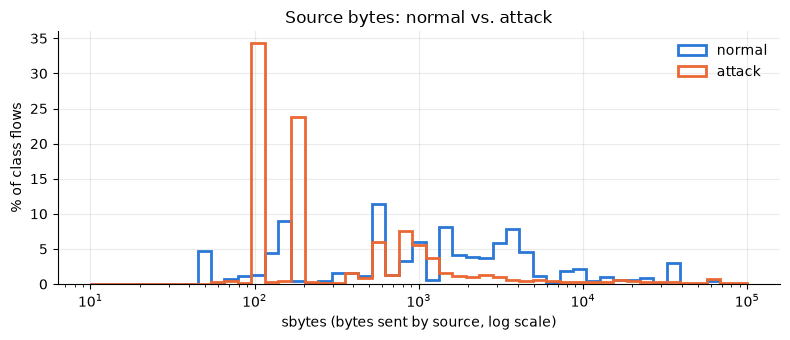

In [9]:
bins = np.logspace(1, 5, 50)  # 10 B to 100 kB
fig, ax = plt.subplots(figsize=(8, 3.5))

for lbl in (0, 1):
    values = train.loc[train["label"] == lbl, "sbytes"]
    weights = np.full(len(values), 100 / len(values))
    ax.hist(values, bins=bins, histtype="step", linewidth=2,
            color=COLORS[lbl], label=NAMES[lbl], weights=weights)

ax.set(
    xscale="log",
    xlabel="sbytes (bytes sent by source, log scale)",
    ylabel="% of class flows",
    title="Source bytes: normal vs. attack",
)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 8. Single-feature predictive power
A **decision stump** (depth-1 tree) asks one threshold question per numeric feature on `train` and is scored on `test` with **balanced accuracy** (`50%` = random guessing, `100%` = perfect).

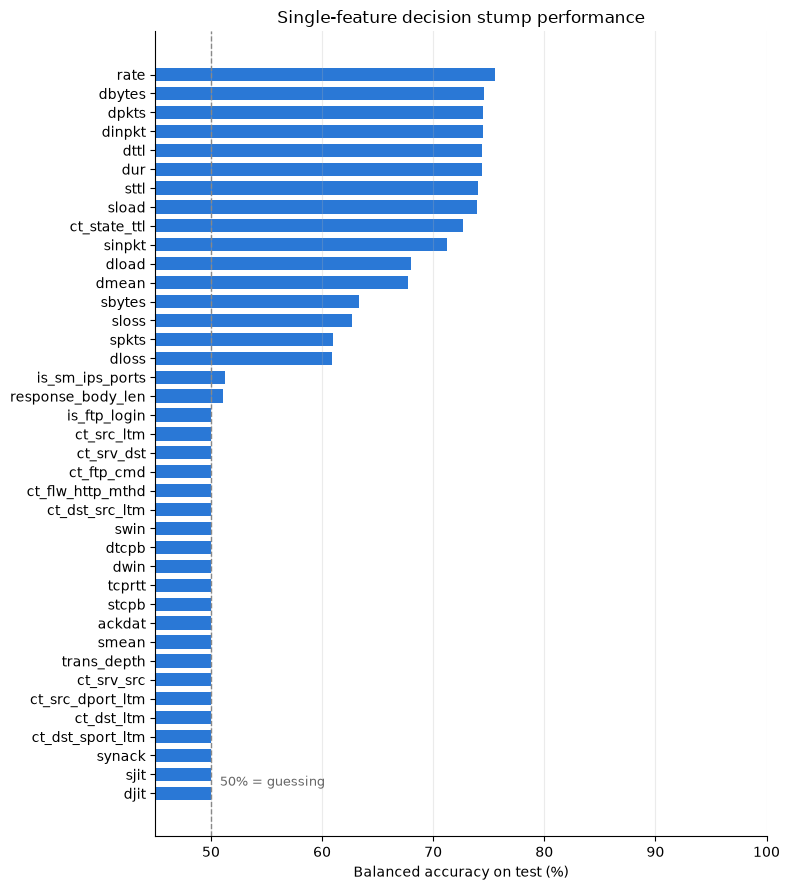

,balanced_acc_%
rate,75.6
dbytes,74.5
dpkts,74.5
dinpkt,74.5
dttl,74.4


In [10]:
numeric_cols = train.select_dtypes("number").columns.drop(["id", "label"])
scores = {}

for col in numeric_cols:
    stump = DecisionTreeClassifier(max_depth=1).fit(train[[col]], train["label"])
    scores[col] = balanced_accuracy_score(test["label"], stump.predict(test[[col]]))

scores = pd.Series(scores).sort_values()

fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(scores.index, scores.values * 100, color=COLORS[0], height=0.7)
ax.axvline(50, color="#888", linewidth=1, linestyle="--")
ax.text(50.8, 0.4, "50% = guessing", color="#666", fontsize=9)
ax.set(
    xlim=(45, 100),
    xlabel="Balanced accuracy on test (%)",
    title="Single-feature decision stump performance",
)
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

scores.sort_values(ascending=False).head(5).mul(100).round(1).rename("balanced_acc_%").to_frame()

## 9. Lab artefact: `sttl`
`sttl` (source packet TTL) is set by the sender's OS, not by whether traffic is malicious. Checking its distribution in `train` reveals a capture-lab shortcut:

In [11]:
pd.crosstab(train["sttl"], train["label"].map(NAMES)).query("attack + normal > 500")

label,attack,normal
sttl,,
0,303,2859
31,0,39455
62,15514,2167
254,103513,11230


In `train`, TTL `31` is 100% normal while `62` and `254` are mostly attacks — an artefact of the lab machines' OS defaults. That shortcut weakens noticeably on `test`:

In [12]:
stump = DecisionTreeClassifier(max_depth=1).fit(train[["sttl"]], train["label"])
print(f"Learned rule: attack if sttl > {stump.tree_.threshold[0]:.1f}")

for split_name, df in [("train", train), ("test", test)]:
    acc = balanced_accuracy_score(df["label"], stump.predict(df[["sttl"]]))
    print(f"{split_name:>5}: {acc:.1%} balanced accuracy")

Learned rule: attack if sttl > 61.0
train: 87.7% balanced accuracy
 test: 74.0% balanced accuracy


## Key takeaways
- **No `NaN`s**, but `service == "-"` is missing in over half of rows.
- **Heavy duplication** (38.6% in train) and **5.2% exact train/test overlap** (leakage).
- **Class shift**: 68.1% attack in train vs. 55.1% in test — track F1 and FPR, not accuracy.
- **Extreme right skew** in byte/packet/rate columns (linear models will need `log1p` + scaling).
- **`sttl` is a lab OS shortcut** that degrades on test and is absent from Zeek `conn.log`.